# Who Should We Target? Predicting High Grocery Spenders for Armando Testa

**IS 4487 Final Project, Fall 2026**

**Team:** Xander Patterson, Andrew Johnson, Hunter Voung, Eddie Yoshioka

**Video presentation:** add the YouTube link here once it's recorded

## Project Overview

Armando Testa is an Italian ad agency. Two of its oldest clients, Lavazza and Barilla, sell coffee, pasta and cookies in grocery stores. When these brands pay for ads, they want the ads to reach the people who spend the most on groceries. Big companies buy shopper data to find those people. Smaller companies often can't afford it.

Our question: can free public data do the same job? We used the U.S. Bureau of Labor Statistics (BLS) Consumer Expenditure Survey to predict if a household is a **high grocery spender**. That means it spends more than the median household (the one in the middle), which spends \$150 a week. We only used five things that ad platforms already let you target: age, income, region, household size and household type. We built three models (logistic regression, a decision tree and k-nearest neighbors), tested them on households they had never seen, and used the best one to make a targeting plan.

The notebook follows the CRISP-DM steps:

| CRISP-DM step | Sections |
|---|---|
| Business understanding | 1 |
| Data understanding | 2, 3, 4 |
| Data preparation | 5 |
| Modeling | 6, 7 |
| Evaluation | 8 |
| Deployment | 9, 10 |

## 1. Business Problem & Context

### The organization

Armando Testa is an advertising company based in Turin, Italy. The designer Armando Testa opened his design studio in 1946 and turned it into an ad agency in 1956 (Armando Testa, n.d.; Giura, 2025). Today it also has offices in Milan, Paris and Los Angeles (Armando Testa, n.d.). Its longest clients are food companies: Lavazza since 1958 and Barilla since 1989, including Barilla's Pan di Stelle cookies (Armando Testa, n.d.). In January 2026 it won back Barilla's Mulino Bianco brand, about 15 years after losing it in 2011 (Galli, 2026). The year before, it bought 30% of RedAbissi, a Turin company that makes software for managing social media posts (Giura, 2025). So the agency is adding tech services on top of its creative work.

### The business challenge

When a grocery brand runs an ad campaign, someone has to decide who sees the ads. Not every household spends the same on groceries. In our data, a typical five-person household spends about two and a half times as much per week as a person living alone (Section 4). So an ad shown to a big spender is worth more.

Big advertisers figure out who to target by buying shopper data and loyalty card data. Mid-sized clients usually don't buy that data, so they end up guessing. Armando Testa needs a cheap, simple way to tell a client which households are most likely to be big grocery spenders, using only details that ad platforms let you target.

### Why it matters

Everyone buys groceries, and groceries are a big part of every budget. The average U.S. household spent \$6,224 on food at home in 2024, up 2.8% from 2023 (BLS, 2025). In 2025, U.S. shoppers spent \$1.10 trillion on food at home (Zeballos & Sinclair, 2026). With that much money involved, moving even part of an ad budget toward big spenders makes a difference. In the survey's detailed spending file, groceries are the biggest single spending line, and almost every household has one (Section 4).

If a model can pick out big spenders from basic facts about a household, a client can spend less on households that buy little and more on the ones that buy a lot. It also gives Armando Testa a data-based service to sell next to its creative work, at a price a mid-sized client can afford.

### Industry and market factors

- Targeting is worth a lot of money. A study in the journal *Marketing Science* found that websites earn 52% less from ads when people turn off the tracking cookies used for targeting (INFORMS, 2020). Advertisers pay more when they know who they're reaching.
- Tracking people online is getting harder. Privacy laws like Europe's GDPR, and browsers like Safari and Firefox that block third-party cookies, limit what agencies can learn about each shopper. Survey data describes households without tracking anyone, so it's still useful for planning.
- Groceries cost more than they used to. Food prices went up 9.9% in 2022 and kept going up, by less than 3% a year, in 2024 and 2025 (Zeballos & Sinclair, 2026). Higher bills mean more grocery money for brands to compete for.
- We picked U.S. data on purpose. BLS gives out household spending data for free, with thousands of rows and clear instructions. Armando Testa also has a Los Angeles office, and the same steps can be run on Italian data later (Section 9).

## 2. Data Sources & References

### Main dataset: BLS Consumer Expenditure Survey, 2024 Interview files

- **Original source:** U.S. Bureau of Labor Statistics, Consumer Expenditure Surveys, Public Use Microdata (PUMD), 2024 Interview files, CSV format: https://www.bls.gov/cex/pumd_data.htm
- **Data dictionary** (what every column and code means): https://www.bls.gov/cex/pumd/ce-pumd-interview-diary-dictionary.xlsx
- **Getting started guide:** https://www.bls.gov/cex/pumd-getting-started-guide.htm

In this survey, BLS asks households (it calls them "consumer units") what they spent over the last three months. The same household can be interviewed up to four times, once every three months. The download has one **FMLI** file for each quarter. Each row is one interview, with about 780 columns. The columns describe the household (the age of the main person answering, called the reference person, plus income, region, household size and household type) and how much it spent in each category.

We use the four files that cover interviews from April 2024 to March 2025 (`fmli242`, `fmli243`, `fmli244` and `fmli251`). We left out the January to March 2024 file (`fmli241x`) because BLS changed how it records grocery spending starting in the second quarter of 2024 (BLS, 2024). The newer files have a grocery total (`GROCERPQ` and `GROCERCQ`) that covers everything bought at a grocery store, food and nonfood. The BLS data dictionary calls it the "updated summary variable taking the place of FDHOME," which was the old food-at-home total. The January file only has the old total and no grocery columns, so it can't be combined with the other four.

BLS blocks automatic downloads, so we downloaded `intrvw24.zip` (53.6 MB, more than 50 files) by hand from the page above. To keep our GitHub repo small, we copied only the four household files we use, unchanged, into `data/fmli24.zip`.

### Supporting dataset: BLS detailed expenditure file

From the same download we also use `mtbi244.csv`. This is the detailed spending file for the October to December 2024 interviews, copied unchanged into `data/mtbi244.zip`. Each row is one purchase line for one household, with `NEWID` (the interview ID), `EXPNAME` (the survey question it came from), `UCC` (a BLS spending code) and `COST` (the dollar amount). Section 4 uses it to see what households spend money on and to double-check our grocery totals.

### Columns we use

| Column | What it means |
|---|---|
| `NEWID` | Interview ID: the household ID plus the interview number as the last digit |
| `AGE_REF` | Age of the main person answering (the reference person) |
| `FINCBTXM` | Household income before taxes (BLS fills in missing answers) |
| `REGION` | 1 = Northeast, 2 = Midwest, 3 = South, 4 = West |
| `FAM_SIZE` | Number of people in the household |
| `FAM_TYPE` | Household type, 9 codes (married couple with kids, single parent, living alone and so on) |
| `GROCERPQ`, `GROCERCQ` | Grocery spending, split into the last calendar quarter and this one |
| `EDUC_REF`, `CUTENURE`, `BLS_URBN`, `NO_EARNR`, `PERSLT18`, `PERSOT64`, `VEHQ` | Education, owns or rents the home, urban or rural, number of people working, kids under 18, people over 64, number of vehicles. Only used in the feature test (Section 7.4) |

### References

1. Galli, E. (2026, January 27). Armando Testa torna al Mulino Bianco. *ItaliaOggi*. https://www.italiaoggi.it/marketing-e-media/marketing/armando-testa-torna-al-mulino-bianco-c9upywno
2. Giura, G. M. (2025, January 22). Il Gruppo Armando Testa acquisisce il 30% della martech RedAbissi, con possibilità di arrivare al 100%. *BeBeez*. https://bebeez.it/ma-e-corporate-finance/il-gruppo-armando-testa-acquisisce-il-30-della-martech-redabissi-con-possibilita-di-arrivare-al100/
3. U.S. Bureau of Labor Statistics. (2025, December 19). *Consumer expenditures, 2024* (USDL-25-1586). https://www.bls.gov/news.release/archives/cesan_12192025.htm
4. U.S. Bureau of Labor Statistics. (2024, September 25). *PUMD errata: FMLI food at home*. https://www.bls.gov/cex/pumd/errata/errata-2023.htm
5. Zeballos, E., & Sinclair, W. (2026, June 1). *Food prices and spending*. USDA Economic Research Service. https://ers.usda.gov/data-products/ag-and-food-statistics-charting-the-essentials/food-prices-and-spending
6. INFORMS. (2020, January 14). *Researchers find that cookies increase ad revenue for online publishers* [News release on Johnson, Shriver and Du, *Marketing Science*]. https://www.informs.org/News-Room/INFORMS-Releases/News-Releases/Researchers-Find-that-Cookies-Increase-Ad-Revenue-for-Online-Publishers
7. Armando Testa. (n.d.). *Home*, *Our clients* and *Contact us*. Retrieved November 11, 2026, from https://www.armandotesta.it/, https://www.armandotesta.it/our-clients/ and https://www.armandotesta.it/contact-us/

Sources 1, 2 and 6 are independent of Armando Testa (two news sites and a research group). Sources 3 to 5 come from U.S. government agencies.

## 3. Data Acquisition & Loading

First we load the libraries we need for loading data, exploring it and making charts. We import the modeling libraries later, right before we use them.

In [1]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Next we open the zip file and list what's inside. Each file holds one quarter (three months) of interviews.

In [2]:
# The four household (FMLI) files from the BLS 2024 interview download
zip_file = zipfile.ZipFile('data/fmli24.zip')
zip_file.namelist()

['fmli242.csv', 'fmli243.csv', 'fmli244.csv', 'fmli251.csv']

Each file has about 780 columns, but we only need 15. Loading just those keeps the table small and easier to work with.

In [3]:
# Each file has about 780 columns, so we only load the ones we need
id_cols = ['NEWID']
feature_cols = ['AGE_REF', 'FINCBTXM', 'REGION', 'FAM_SIZE', 'FAM_TYPE']
extra_cols = ['EDUC_REF', 'CUTENURE', 'BLS_URBN', 'NO_EARNR', 'PERSLT18', 'PERSOT64', 'VEHQ']
grocery_cols = ['GROCERPQ', 'GROCERCQ']

keep_cols = id_cols + feature_cols + extra_cols + grocery_cols
print(len(keep_cols), 'columns')

15 columns


Now we read each file, keeping only our 15 columns (`usecols`), and stack the four quarters into one table with `pd.concat`. We also add the file name to each row so we know which quarter it came from.

In [4]:
# Read each quarter's file and stack them into one table
frames = []
for name in zip_file.namelist():
    quarter = pd.read_csv(zip_file.open(name), usecols=keep_cols)
    quarter['file'] = name
    frames.append(quarter)
    print(name, quarter.shape)

df = pd.concat(frames, ignore_index=True)
print('Stacked:', df.shape)

fmli242.csv (4673, 16)
fmli243.csv (4612, 16)


fmli244.csv (4601, 16)


fmli251.csv (4602, 16)
Stacked: (18488, 16)


In [5]:
df.head()

,NEWID,AGE_REF,BLS_URBN,CUTENURE,EDUC_REF,FAM_SIZE,FAM_TYPE,NO_EARNR,PERSLT18,PERSOT64,REGION,VEHQ,FINCBTXM,GROCERPQ,GROCERCQ,file
0,5411714,31,1,4,16,1,8,1,0,0,4.0,1,100903.0,1521.0,0.0,fmli242.csv
1,5411724,34,1,1,14,3,2,2,1,0,4.0,3,105400.0,1300.0,0.0,fmli242.csv
2,5411734,77,1,1,12,2,1,0,0,2,3.0,5,68192.0,1300.0,0.0,fmli242.csv
3,5411764,52,1,4,16,1,8,1,0,0,2.0,1,61000.0,1340.0,0.0,fmli242.csv
4,5411834,40,2,1,10,12,4,2,9,0,2.0,1,166801.6,3250.0,0.0,fmli242.csv


## 4. Data Exploration (EDA)

First we look at how the table is built. Then we look at grocery spending and how it changes with each household detail. We also explore a second BLS file that lists every purchase. As we go, we write down the problems we'll fix in Section 5.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18488 entries, 0 to 18487
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   NEWID     18488 non-null  int64  
 1   AGE_REF   18488 non-null  int64  
 2   BLS_URBN  18488 non-null  int64  
 3   CUTENURE  18488 non-null  int64  
 4   EDUC_REF  18488 non-null  int64  
 5   FAM_SIZE  18488 non-null  int64  
 6   FAM_TYPE  18488 non-null  int64  
 7   NO_EARNR  18488 non-null  int64  
 8   PERSLT18  18488 non-null  int64  
 9   PERSOT64  18488 non-null  int64  
 10  REGION    18135 non-null  float64
 11  VEHQ      18488 non-null  int64  
 12  FINCBTXM  18488 non-null  float64
 13  GROCERPQ  18488 non-null  float64
 14  GROCERCQ  18488 non-null  float64
 15  file      18488 non-null  object 
dtypes: float64(4), int64(11), object(1)
memory usage: 2.3+ MB


The table has 18,488 rows (one per interview) and 16 columns. Everything loaded as numbers except the file name. `REGION` and `FAM_TYPE` are numbers too, but each number stands for a group, so later we'll treat them as categories. `REGION` is the only column with blanks.

In [7]:
df.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
NEWID,18488.0,5697885.5,135984.2,5411714.0,5586520.0,5674221.5,5821301.2,5981451.0
AGE_REF,18488.0,54.2,17.9,16.0,39.0,55.0,68.0,88.0
BLS_URBN,18488.0,1.1,0.2,1.0,1.0,1.0,1.0,2.0
CUTENURE,18488.0,2.3,1.3,1.0,1.0,2.0,4.0,6.0
EDUC_REF,18488.0,13.7,1.8,0.0,12.0,14.0,15.0,16.0
FAM_SIZE,18488.0,2.3,1.4,1.0,1.0,2.0,3.0,16.0
FAM_TYPE,18488.0,5.3,3.2,1.0,2.0,7.0,8.0,9.0
NO_EARNR,18488.0,1.2,1.0,0.0,0.0,1.0,2.0,7.0
PERSLT18,18488.0,0.5,0.9,0.0,0.0,0.0,1.0,13.0
PERSOT64,18488.0,0.5,0.7,0.0,0.0,0.0,1.0,3.0


A few things stand out:

- Ages go from 16 to 88.
- The median income (`FINCBTXM`) is \$75,000, but incomes go as low as -\$25,169 (a business loss) and as high as \$963,420.
- Households have 1 to 16 people.
- `VEHQ` (number of vehicles) goes up to 23, which looks strange. We only use it in the feature test, so we left it alone.
- Grocery spending is split into two columns that we need to add together.

In [8]:
df.isnull().sum()

NEWID         0
AGE_REF       0
BLS_URBN      0
CUTENURE      0
EDUC_REF      0
FAM_SIZE      0
FAM_TYPE      0
NO_EARNR      0
PERSLT18      0
PERSOT64      0
REGION      353
VEHQ          0
FINCBTXM      0
GROCERPQ      0
GROCERCQ      0
file          0
dtype: int64

Only `REGION` has missing values: 353 of 18,488 rows, about 1.9%. That's a small number, so we'll drop those rows instead of guessing a region.

In [9]:
# The last digit of NEWID is the interview number, the rest is the household
df['cu_id'] = df['NEWID'] // 10

times_seen = df['cu_id'].value_counts()
print('Unique households:', df['cu_id'].nunique())
times_seen.value_counts().sort_index()

Unique households: 10116


count
1    4786
2    2912
3    1794
4     624
Name: count, dtype: int64

Some households show up more than once. The 18,488 interviews came from 10,116 different households: 4,786 show up once, 2,912 twice, 1,794 three times and 624 four times. If we kept every interview, the same household could end up in both the training set and the test set. Then the models would look better than they really are. So we'll keep one interview per household.

In [10]:
# Grocery spending for the 3 months before the interview is split into two parts:
# the part that fell in the previous calendar quarter (PQ) and the current one (CQ)
df['grocery_3mo'] = df['GROCERPQ'] + df['GROCERCQ']
df['weekly_grocery'] = df['grocery_3mo'] / 13

df['weekly_grocery'].describe().round(2)

count    18488.00
mean       177.54
std        126.56
min          0.00
25%        100.00
50%        150.00
75%        225.00
max       2000.00
Name: weekly_grocery, dtype: float64

The survey asks how much the household spent on groceries in the three months before the interview. BLS splits that amount into two parts: the part from the last calendar quarter (PQ) and the part from this one (CQ). Adding them gives the three-month total. Dividing by 13 weeks turns it into a weekly number, which is easier to understand. The median answer is \$150 a week, and the middle half of answers fall between \$100 and \$225.

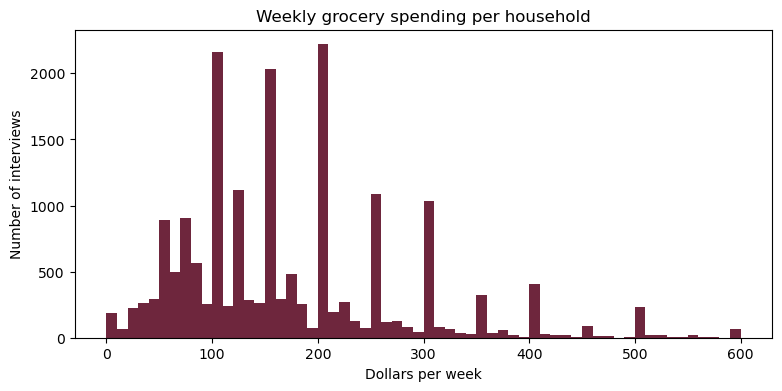

In [11]:
plt.figure(figsize=(9, 4))
plt.hist(df['weekly_grocery'], bins=60, range=(0, 600), color='#6e263d')
plt.title('Weekly grocery spending per household')
plt.xlabel('Dollars per week')
plt.ylabel('Number of interviews')
plt.show()

Most households spend about \$50 to \$300 a week, and a few spend a lot more. The tall, thin spikes tell us something about how people answer.

In [12]:
# The ten most common answers
df['weekly_grocery'].round(2).value_counts().head(10)

weekly_grocery
200.0    1973
100.0    1909
150.0    1774
250.0     940
300.0     925
50.0      733
75.0      563
125.0     507
120.0     457
80.0      367
Name: count, dtype: int64

People answer with round numbers. \$200, \$100 and \$150 a week are by far the three most common answers. That makes sense, because the survey asks for the household's usual grocery cost (BLS, 2024) and people just estimate. This matters for our target: so many people say exactly \$150 that a lot of households will land right on the median when we make the high spender label.

In [13]:
df.groupby('FAM_SIZE')['weekly_grocery'].agg(['count', 'median']).round(1)

,count,median
FAM_SIZE,,
1,5908,98.4
2,6491,150.0
3,2608,200.0
4,2064,226.8
5,893,250.0
6,333,275.4
7,129,350.0
8,39,298.5
9,10,300.0


Spending goes up with each extra person, from a median of \$98.40 a week for one person to \$250 for five people. Only a few households have 8 or more people (39 interviews or fewer), so their numbers jump around.

In [14]:
# Split income into five equal-sized groups and compare spending
income_groups = pd.qcut(df['FINCBTXM'], 5)
df.groupby(income_groups, observed=True)['weekly_grocery'].agg(['count', 'median']).round(1)

,count,median
FINCBTXM,,
"(-25168.901, 30089.76]",3698,100.0
"(30089.76, 57811.4]",3697,125.0
"(57811.4, 96174.24]",3698,150.0
"(96174.24, 160200.0]",3698,187.6
"(160200.0, 963420.0]",3697,208.8


Income matters too. The bottom fifth of interviews (income up to about \$30,000) has a median of \$100 a week. The top fifth (above \$160,200) has a median of \$208.80.

In [15]:
df.groupby('FAM_TYPE')['weekly_grocery'].agg(['count', 'median']).round(1)

,count,median
FAM_TYPE,,
1,4442,153.8
2,617,200.0
3,1885,250.0
4,1285,220.0
5,726,229.0
6,178,160.0
7,532,177.3
8,5908,98.4
9,2915,151.9


Household type follows household size. Married couples whose oldest child is 6 to 17 (code 3) spend the most, with a median of \$250 a week. People living alone (code 8) spend the least at \$98.40. In Section 5 we'll swap these code numbers for names.

In [16]:
df.groupby('REGION')['weekly_grocery'].agg(['count', 'median']).round(1)

,count,median
REGION,,
1.0,2873,150.0
2.0,3489,150.0
3.0,6607,150.0
4.0,5166,175.0


Region doesn't change much. The Northeast (1), Midwest (2) and South (3) all have a median of \$150, and the West (4) is a little higher at \$175.

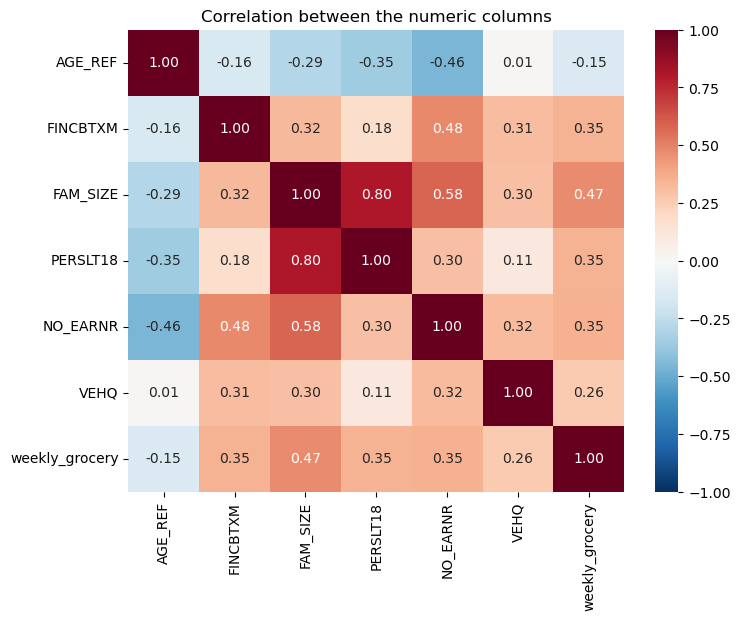

In [17]:
num_cols = ['AGE_REF', 'FINCBTXM', 'FAM_SIZE', 'PERSLT18', 'NO_EARNR', 'VEHQ', 'weekly_grocery']

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlation between the numeric columns')
plt.show()

This chart shows how closely each pair of columns moves together, on a scale from -1 to 1. Household size has the strongest link to weekly grocery spending (0.47). Next come income, kids under 18 and number of people working (0.35 each). Age has a small negative link (-0.15), so older households spend a little less. Household size and kids under 18 move together a lot (0.80), so they mostly tell us the same thing. We'll remember that when we test extra features later.

In [18]:
print('Negative incomes:', (df['FINCBTXM'] < 0).sum())
print('Incomes above $500,000:', (df['FINCBTXM'] > 500000).sum())
print('Highest income:', df['FINCBTXM'].max())
print('Households reporting $0 for groceries:', (df['grocery_3mo'] == 0).sum())
print('Weekly grocery above $1,000:', (df['weekly_grocery'] > 1000).sum())

Negative incomes: 7
Incomes above $500,000: 207
Highest income: 963420.0
Households reporting $0 for groceries: 153
Weekly grocery above $1,000: 27


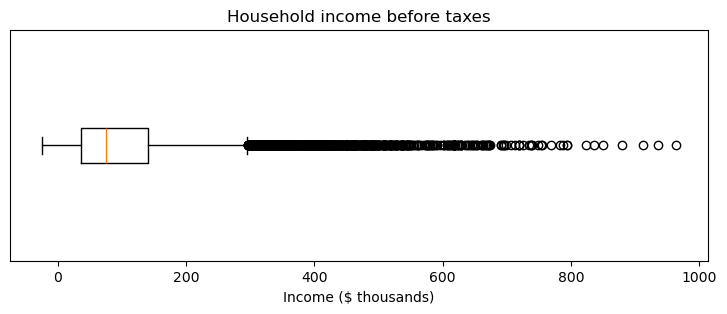

In [19]:
plt.figure(figsize=(9, 3))
plt.boxplot(df['FINCBTXM'] / 1000, vert=False)
plt.title('Household income before taxes')
plt.xlabel('Income ($ thousands)')
plt.yticks([])
plt.show()

### A second BLS file: what households spend on

Before we picked grocery spending, we explored a second file from the same BLS download, the detailed spending file (MTBI). Each row is one purchase line: the household (`NEWID`), the survey question (`EXPNAME`), a BLS spending code (`UCC`) and the amount (`COST`). We used the October to December 2024 file (`mtbi244`) to see which households and categories have the most spending. It also lets us double-check our grocery numbers.

In [20]:
# Detailed expense lines for the October to December 2024 interviews
mtbi = pd.read_csv('data/mtbi244.zip')
print(mtbi.shape)
mtbi[['NEWID', 'EXPNAME', 'UCC', 'COST']].head()

(360558, 13)


,NEWID,EXPNAME,UCC,COST
0,5573644,QRT3MCMX,210110,1300.0
1,5573644,QRT3MCMX,210110,1300.0
2,5573644,QRT3MCMX,210110,1300.0
3,5573664,QRT3MCMX,210110,1600.0
4,5573664,QRT3MCMX,210110,1600.0


That's 360,558 purchase lines from one quarter of interviews.

In [21]:
# Add up each expense name across all households, largest first
categories = mtbi.groupby('EXPNAME')['COST'].agg(['sum', 'count'])
categories.sort_values('sum', ascending=False).head(10).round(0)

,sum,count
EXPNAME,,
PROPVALX,404943630.0,9213
JCPIRE1X,23933648.0,9597
ORGMRTX,15893998.0,54
OWN_PURX,10675527.0,25
JGREXPQV,10558239.0,13698
QTRADEX,9006702.0,403
QRT3MCMX,6182367.0,4404
JFDBAWQV,4867989.0,11757
QADLABX,4854042.0,1198


At first, the biggest "expenses" look like `PROPVALX`, `JCPIRE1X`, `ORGMRTX` and `OWN_PURX`. But the BLS data dictionary shows these aren't purchases. `PROPVALX` is what a home would sell for today. `JCPIRE1X` is a guess at what an owned home would rent for. `ORGMRTX` is the size of a mortgage, and `OWN_PURX` is the price of a property. Two lines just below the top 10 are the same kind of thing: `RNTEQVX` (another rent guess) and `PRINCIPX` (the amount borrowed for a car). If we counted these as spending, homeowners would look like the biggest spenders by far. So we take them out.

In [22]:
# These are values, estimates and loan amounts. None of them is money spent (BLS data dictionary)
not_spending = ['PROPVALX', 'JCPIRE1X', 'RNTEQVX', 'ORGMRTX', 'OWN_PURX', 'PRINCIPX']
spending = mtbi[~mtbi['EXPNAME'].isin(not_spending)]
print('Lines removed:', len(mtbi) - len(spending))

per_household = spending.groupby('NEWID')['COST'].sum()
print('Households:', len(per_household))
print('Median per household with those lines left in: $', round(mtbi.groupby('NEWID')['COST'].sum().median()))
print('Median per household without them: $', round(per_household.median()))

Lines removed: 28833
Households: 4601
Median per household with those lines left in: $ 86360
Median per household without them: $ 13750


Taking out those 28,833 lines changes things a lot. With them in, the median household "spent" \$86,360 in three months, mostly because of home values. With them out, it's \$13,750.

In [23]:
# How much of all the spending comes from the top 20% of households?
ranked = per_household.sort_values(ascending=False)
top_fifth = ranked.head(int(len(ranked) * 0.2))
print('Share of all spending from the top 20% of households:', round(top_fifth.sum() / ranked.sum(), 3))

Share of all spending from the top 20% of households: 0.495


A small group of households does most of the spending. The top 20% of households make up 49.5% of all spending in the quarter. That's why targeting matters.

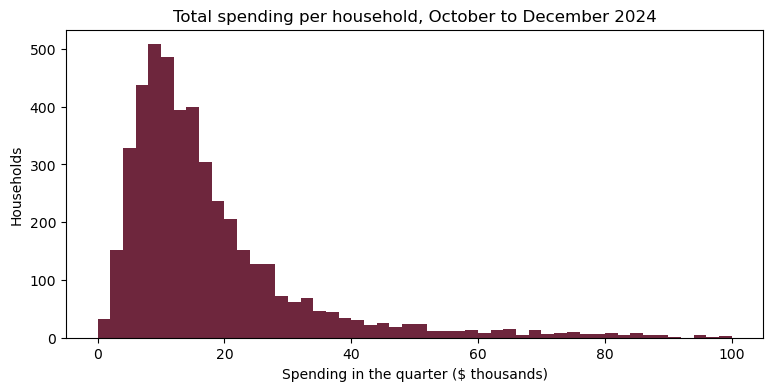

Middle 80% of households: $ 5717 to $ 35577
Households above $100,000: 46
Households below $0: 10


In [24]:
plt.figure(figsize=(9, 4))
plt.hist(per_household / 1000, bins=50, range=(0, 100), color='#6e263d')
plt.title('Total spending per household, October to December 2024')
plt.xlabel('Spending in the quarter ($ thousands)')
plt.ylabel('Households')
plt.show()

print('Middle 80% of households: $', round(per_household.quantile(0.1)), 'to $', round(per_household.quantile(0.9)))
print('Households above $100,000:', (per_household > 100000).sum())
print('Households below $0:', (per_household < 0).sum())

Most households (the middle 80%) spend between about \$5,700 and \$35,600 in the quarter, and a few spend much more. The chart stops at \$100,000. 46 households are above that, and 10 come out below zero because some lines in the file are stored as negative amounts.

In [25]:
# The biggest real spending lines, and how many households have each one
top_spending = spending.groupby('EXPNAME').agg(total=('COST', 'sum'), households=('NEWID', 'nunique'))
top_spending = top_spending.sort_values('total', ascending=False).head(10)
top_spending.round(0)

,total,households
EXPNAME,,
JGREXPQV,10558239.0,4566
QTRADEX,9006702.0,257
QRT3MCMX,6182367.0,1443
JFDBAWQV,4867989.0,3919
QADLABX,4854042.0,727
QADPTAX,3514158.0,3006
QHHP3MX,3169318.0,2652
JFCENMQV,3086902.0,823
CONTEXPX,2966162.0,2099


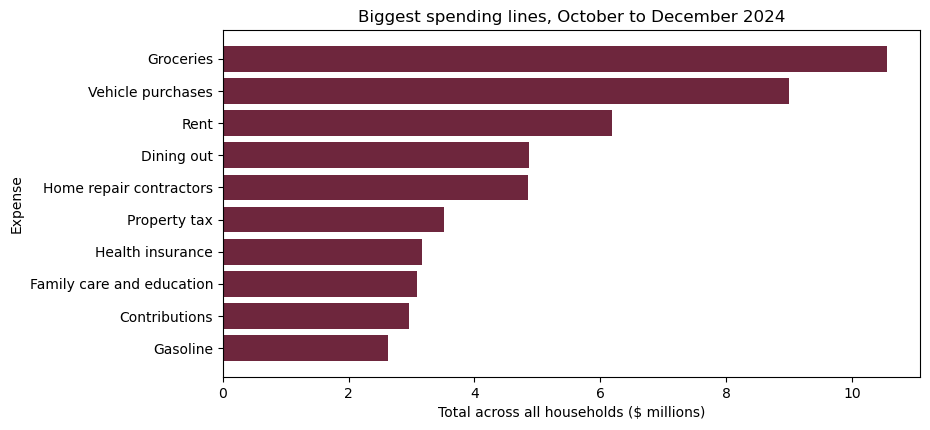

In [26]:
# Short names based on the BLS data dictionary descriptions
expense_names = {'JGREXPQV': 'Groceries', 'QTRADEX': 'Vehicle purchases', 'QRT3MCMX': 'Rent',
                 'JFDBAWQV': 'Dining out', 'QADLABX': 'Home repair contractors', 'QADPTAX': 'Property tax',
                 'QHHP3MX': 'Health insurance', 'JFCENMQV': 'Family care and education',
                 'CONTEXPX': 'Contributions', 'JGASOXQV': 'Gasoline'}
plt.figure(figsize=(9, 4.5))
plt.barh([expense_names[n] for n in top_spending.index[::-1]], top_spending['total'][::-1] / 1e6, color='#6e263d')
plt.title('Biggest spending lines, October to December 2024')
plt.xlabel('Total across all households ($ millions)')
plt.ylabel('Expense')
plt.show()

With the home values and loans gone, groceries are the biggest spending line in the quarter, about \$10.6 million in total. 4,566 of the 4,601 households have a grocery line. The bigger purchases come from far fewer households. For example, only 257 households bought a vehicle.

In [27]:
# BLS builds each household's grocery total from two spending codes (data dictionary):
# 790210 = grocery store purchases, 190904 = groceries bought on trips
grocery_lines = mtbi[mtbi['UCC'].isin([790210, 190904])].groupby('NEWID')['COST'].sum()
q4_grocery = df[df['file'] == 'fmli244.csv'].set_index('NEWID')['grocery_3mo']

check = pd.concat([q4_grocery, grocery_lines], axis=1).fillna(0)
check.columns = ['household_file', 'detail_file']
gap = (check['household_file'] - check['detail_file']).abs()
print('Households that match to the dollar:', (gap < 1).sum(), 'of', len(check))

Households that match to the dollar: 4601 of 4601


All 4,601 households match to the dollar. So the grocery total we use in the rest of the notebook is exactly the sum of the grocery lines in the detailed file. That tells us we built our target correctly.

Groceries are the one big expense almost every household has, and a small group of households does about half of all spending. So grocery brands sell to almost everyone, and it helps a lot to know which households spend the most. We don't use this file in the models, because the household file already has the same grocery total plus the household details we need.

### Problems to fix in the household file

1. Repeated households: 10,116 households gave the 18,488 interviews. Keep one interview each.
2. Missing region: 353 interviews have no region. Drop them.
3. Negative income: 7 interviews report income below zero, usually from a business loss. They don't make sense for a model based on income, so we drop them.
4. Very high incomes: 207 interviews report more than \$500,000, and the highest is \$963,420. The box plot shows how far out they are. These are real households, so we keep them. But we cap income at the 99th percentile so a few huge values don't throw off logistic regression and KNN.
5. Extreme grocery answers: 153 interviews report \$0 on groceries and 27 report more than \$1,000 a week. Our target only asks if a household is above or below the median, so these values can't throw off the label. We leave them in.
6. Numbers that are really categories: `REGION` and `FAM_TYPE` are stored as numbers but stand for groups, so we turn them into yes/no columns (one-hot encoding).

## 5. Data Cleaning & Preprocessing

We fix the problems from Section 4 one at a time. After each step we print how many rows are left, so we know nothing went missing by accident.

In [28]:
# Keep each household's most recent interview (highest NEWID)
print('Rows before:', len(df))
df = df.sort_values('NEWID').drop_duplicates(subset='cu_id', keep='last')
print('Rows after keeping one interview per household:', len(df))

Rows before: 18488
Rows after keeping one interview per household: 10116


Now each household shows up once, 10,116 in all. We kept each household's most recent interview because it has the newest information.

In [29]:
df = df.dropna(subset=['REGION'])
print('Rows after dropping blank regions:', len(df))

Rows after dropping blank regions: 9930


In [30]:
df = df[df['FINCBTXM'] >= 0]
print('Rows after dropping negative incomes:', len(df))

Rows after dropping negative incomes: 9923


Dropping 186 households with no region and 7 with negative income leaves 9,923 households.

In [31]:
# Cap income at the 99th percentile so a few very high earners don't stretch the scale
income_cap = df['FINCBTXM'].quantile(0.99)
print('99th percentile income:', round(income_cap))
print('Households above it:', (df['FINCBTXM'] > income_cap).sum())

df['income'] = df['FINCBTXM'].clip(upper=income_cap)
df['income'].describe().round(0)

99th percentile income: 523628
Households above it: 99


count      9923.0
mean     105722.0
std      101453.0
min           0.0
25%       36007.0
50%       74000.0
75%      139504.0
max      523628.0
Name: income, dtype: float64

The 99th percentile is \$523,628, and 99 households were above it. Their income is now set to \$523,628. They're still the top earners, just closer to everyone else. We kept the original income column (`FINCBTXM`) and use the new `income` column in the models.

### Feature engineering

Next we make our target and a few new columns:

- `weekly_grocery`: the three-month grocery total divided by 13 (made in Section 4)
- `high_spender`: 1 if the household spends more than the median each week, 0 if not
- `region` and `household_type`: names in place of the BLS code numbers
- `owns_home` and `rural`: two simple yes/no columns for the feature test

In [32]:
# Target: does the household spend more than the median per week on groceries?
median_weekly = df['weekly_grocery'].median()
print('Median weekly grocery spending: $', median_weekly)

df['high_spender'] = (df['weekly_grocery'] > median_weekly).astype(int)
df['high_spender'].value_counts()

Median weekly grocery spending: $ 150.0


high_spender
0    5342
1    4581
Name: count, dtype: int64

In [33]:
print('Households exactly at the median:', (df['weekly_grocery'] == median_weekly).sum())
print('Share labeled high spenders:', round(df['high_spender'].mean(), 3))

Households exactly at the median: 941
Share labeled high spenders: 0.462


The median is \$150 a week, so a high spender is a household that spends more than \$150 a week on groceries. 941 households report exactly \$150, and they all go in the "not high" group. That's why the split is 4,581 high spenders to 5,342 others (46.2%) instead of an even 50/50. That's still close to even, so we don't need to rebalance it.

In [34]:
# Swap the BLS code numbers for readable names (from the BLS data dictionary)
region_names = {1: 'Northeast', 2: 'Midwest', 3: 'South', 4: 'West'}
type_names = {1: 'Married couple, no kids', 2: 'Married, oldest child under 6',
              3: 'Married, oldest child 6-17', 4: 'Married, adult children',
              5: 'Other married-couple home', 6: 'Single dad, kids under 18',
              7: 'Single mom, kids under 18', 8: 'Lives alone', 9: 'Other household'}
df['region'] = df['REGION'].map(region_names)
df['household_type'] = df['FAM_TYPE'].map(type_names)
df[['region', 'household_type']].isnull().sum()

region            0
household_type    0
dtype: int64

In [35]:
df = df.rename(columns={'AGE_REF': 'age', 'FAM_SIZE': 'household_size'})

# Two simple flags we test later in feature selection
df['owns_home'] = df['CUTENURE'].isin([1, 2, 3]).astype(int)
df['rural'] = (df['BLS_URBN'] == 2).astype(int)
df[['age', 'income', 'household_size', 'region', 'household_type', 'high_spender']].head()

,age,income,household_size,region,household_type,high_spender
0,31,100903.0,1,West,Lives alone,0
1,34,105400.0,3,West,"Married, oldest child under 6",0
2,77,68192.0,2,South,"Married couple, no kids",0
3,52,61000.0,1,Midwest,Lives alone,0
4,40,166801.6,12,Midwest,"Married, adult children",1


The names come from the BLS data dictionary. Nothing came back blank, so every code matched a name. We also renamed `AGE_REF` and `FAM_SIZE` to `age` and `household_size` so the results are easier to read.

In [36]:
# One-hot encode the two text columns so the models can use them
model_cols = ['age', 'income', 'household_size', 'region', 'household_type']
X = pd.get_dummies(df[model_cols], columns=['region', 'household_type'],
                   prefix=['region', 'type'], prefix_sep=': ', dtype=int)
y = df['high_spender']

print(X.shape)
X.columns.tolist()

(9923, 16)


['age',
 'income',
 'household_size',
 'region: Midwest',
 'region: Northeast',
 'region: South',
 'region: West',
 'type: Lives alone',
 'type: Married couple, no kids',
 'type: Married, adult children',
 'type: Married, oldest child 6-17',
 'type: Married, oldest child under 6',
 'type: Other household',
 'type: Other married-couple home',
 'type: Single dad, kids under 18',
 'type: Single mom, kids under 18']

One-hot encoding turns region into 4 yes/no columns and household type into 9. So `X` has 16 columns: age, income, household size and the 13 yes/no columns. We kept every category (no `drop_first`) so each one shows up by name in the results.

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))

Training rows: 7938
Test rows: 1985


We set aside 20% of households (1,985) as a test set and train on the other 7,938. `stratify=y` makes sure both sets have the same share of high spenders. We don't touch the test set until Section 8.

In [38]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on the training rows only, then apply it to both sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[['mean', 'std']].round(2)

,age,income,household_size,region: Midwest,region: Northeast,region: South,region: West,type: Lives alone,"type: Married couple, no kids","type: Married, adult children","type: Married, oldest child 6-17","type: Married, oldest child under 6",type: Other household,type: Other married-couple home,"type: Single dad, kids under 18","type: Single mom, kids under 18"
mean,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


KNN compares households by how far apart their numbers are. Without scaling, income (in the hundreds of thousands) would count way more than household size (1 to 16). Logistic regression also works better with scaled data, and scaling lets us compare its coefficients to each other. After `StandardScaler`, every column has an average of 0 and a standard deviation of 1. The decision tree only asks yes/no questions about one column at a time, so it doesn't need scaling and uses the original numbers.

## 6. Modeling Approach

Our target is yes or no (high spender or not), so this is a classification problem. We picked three models from class that work in different ways:

| Model | Why we picked it |
|---|---|
| Logistic regression | A simple model and a good place to start. It gives each household a chance of being a high spender, which is what you need to rank an audience. Its coefficients also show which features push spending up or down. |
| Decision tree | Makes yes/no rules, like "more than two people and income above a certain amount." Rules like that are easy to explain to a client. A tree can also find combinations of features that a straight-line model misses. |
| K-nearest neighbors (KNN) | Labels a household by looking at the most similar households in the training data. It doesn't assume any shape for the pattern. |

### How we test the models

We split the data once: 80% for training and 20% for testing. All tuning happens on the training set with 5-fold cross-validation. That means we cut the training set into 5 parts, train on 4 and score on the fifth, and do that 5 times so every part gets a turn. We pick each model's settings by its average score, and only then test all three on the test set.

### What we measure

Accuracy is the main number: how many households the model gets right. For ad targeting, precision matters a lot too. Of the households the model calls high spenders, how many really are? Every wrong "yes" is ad money spent on someone who doesn't buy much. Recall is how many of the real high spenders the model finds. F1 is a mix of precision and recall. ROC AUC measures how well the model ranks households from most likely to least likely.

In [39]:
# A model has to beat this: always guess "not a high spender"
baseline = 1 - y_test.mean()
print('Baseline accuracy:', round(baseline, 3))

Baseline accuracy: 0.539


53.9% of test households are not high spenders. So a "model" that always says no would be right 53.9% of the time. Our models need to beat that.

## 7. Model Implementation

For each model we start with the default settings, tune the settings that matter most, and then train the final version on the whole training set.

### 7.1 Logistic regression

First we try the default settings, scored with 5-fold cross-validation on the scaled training data.

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

log_reg = LogisticRegression(max_iter=1000)
scores = cross_val_score(log_reg, X_train_scaled, y_train, cv=5)
lr_cv_accuracy = scores.mean()
print('Accuracy in each of the 5 folds:', scores.round(3))
print('Average:', lr_cv_accuracy.round(4))

Accuracy in each of the 5 folds: [0.731 0.733 0.725 0.715 0.735]
Average: 0.7278


The five scores are between 71.5% and 73.5%, so the model does about the same on every part of the data. The average is 72.78%, about 19 points better than always guessing no.

In [41]:
# C controls how hard the model is held back. Smaller C = simpler model.
for c in [0.001, 0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=c, max_iter=1000)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    print('C =', c, ' average accuracy:', scores.mean().round(4))

C = 0.001  average accuracy: 0.7254
C = 0.01  average accuracy: 0.7264
C = 0.1  average accuracy: 0.7276
C = 1  average accuracy: 0.7278
C = 10  average accuracy: 0.7278


`C` controls how much the model is held back. A small `C` holds it back a lot, and a big `C` barely holds it back. We tried 0.001 to 10. Accuracy hardly changes: 72.54% at the smallest and 72.78% at C = 1 and C = 10. We have 7,938 households and only 16 columns, so the model isn't overfitting much. We kept the default, **C = 1**.

In [42]:
log_reg = LogisticRegression(C=1, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Coefficients are on the scaled features, so their sizes can be compared
coefs = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()
coefs.round(3)

type: Lives alone                     -0.387
region: Midwest                       -0.068
age                                   -0.048
region: South                         -0.043
type: Other household                 -0.000
type: Single dad, kids under 18        0.022
type: Married, oldest child under 6    0.023
region: Northeast                      0.023
type: Other married-couple home        0.025
region: West                           0.087
type: Single mom, kids under 18        0.088
type: Married couple, no kids          0.127
type: Married, adult children          0.133
type: Married, oldest child 6-17       0.221
income                                 0.419
household_size                         0.575
dtype: float64

A positive coefficient pushes a household toward "high spender," and a negative one pushes it away. Household size (0.575) and income (0.419) push the most. Living alone (-0.387) pushes the most the other way. Married couples whose oldest child is 6 to 17 get an extra push (0.221) beyond what their household size already explains. Region and age matter a lot less.

### 7.2 Decision tree

We start with a tree that has no limits, just to see what happens.

In [43]:
from sklearn.tree import DecisionTreeClassifier

full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)
print('Depth:', full_tree.get_depth(), '  Leaves:', full_tree.get_n_leaves())
print('Training accuracy:', round(full_tree.score(X_train, y_train), 4))
print('5-fold accuracy:', cross_val_score(full_tree, X_train, y_train, cv=5).mean().round(4))

Depth: 29   Leaves: 2415
Training accuracy: 0.9991
5-fold accuracy: 0.6272


That's overfitting. The tree with no limits is 29 levels deep with 2,415 leaves. It gets 99.9% of the training households right but only 62.7% in cross-validation, about 10 points worse than logistic regression. It memorized the training data instead of learning the pattern. Limiting how deep it can grow should help.

In [44]:
for depth in [2, 3, 4, 5, 6, 8, 10]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(tree, X_train, y_train, cv=5)
    print('max_depth =', depth, ' average accuracy:', scores.mean().round(4))

max_depth = 2  average accuracy: 0.6932
max_depth = 3  average accuracy: 0.7197
max_depth = 4  average accuracy: 0.7174
max_depth = 5  average accuracy: 0.7171


max_depth = 6  average accuracy: 0.7158
max_depth = 8  average accuracy: 0.712


max_depth = 10  average accuracy: 0.6883


Accuracy jumps from 69.3% at depth 2 to 71.97% at depth 3. After that it slowly drops as the tree gets deeper (68.8% at depth 10), because deeper trees start splitting on tiny groups again.

In [45]:
# Try depth and minimum leaf size together (min_samples_leaf = fewest households allowed in a leaf)
rows = []
for depth in [3, 4, 5, 6, 8]:
    for leaf in [1, 50, 100, 200]:
        tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=42)
        rows.append([depth, leaf, cross_val_score(tree, X_train, y_train, cv=5).mean()])

grid = pd.DataFrame(rows, columns=['max_depth', 'min_samples_leaf', 'accuracy'])
grid.pivot(index='max_depth', columns='min_samples_leaf', values='accuracy').round(4)

min_samples_leaf,1,50,100,200
max_depth,,,,
3,0.7197,0.7197,0.7197,0.7197
4,0.7174,0.7179,0.7179,0.7186
5,0.7171,0.7207,0.7215,0.7201
6,0.7158,0.7207,0.7216,0.7160
8,0.7120,0.7126,0.7211,0.7154


Setting a minimum number of households per leaf lets the tree grow deeper without chasing tiny groups. The best mix is **max_depth = 6 with min_samples_leaf = 100** (72.16%). Depth 3 is close at 71.97% and is a much smaller tree, but we went with the best score.

Leaves in the final tree: 38


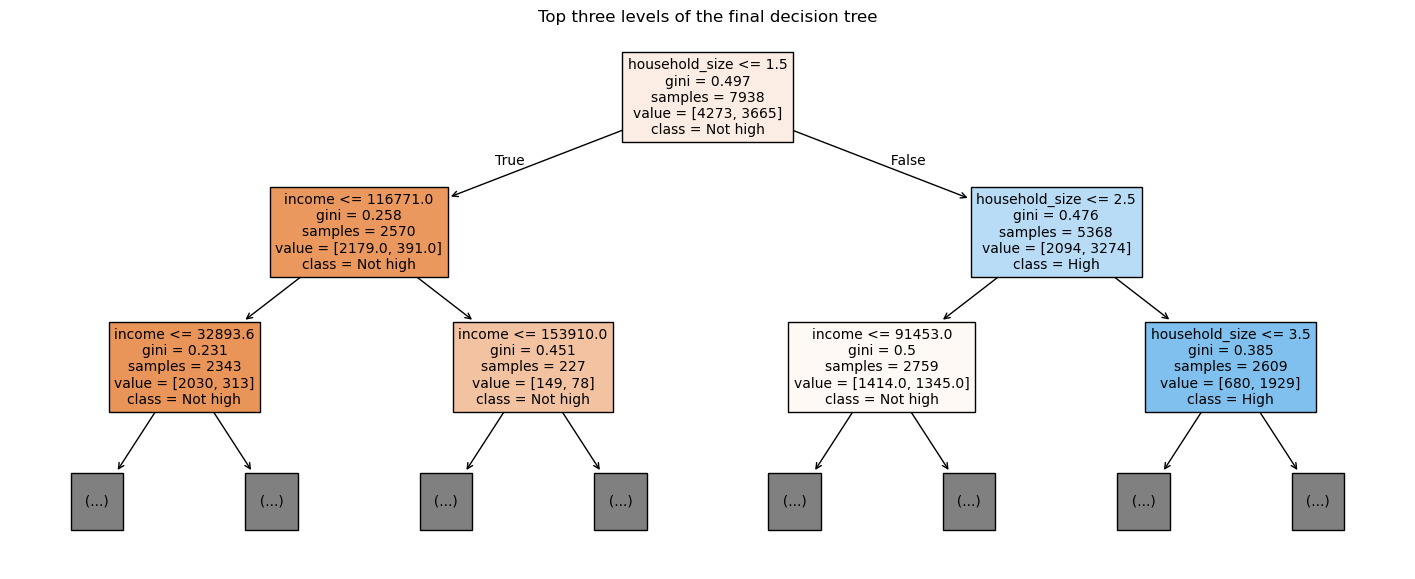

In [46]:
from sklearn.tree import plot_tree

tree_model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=42)
tree_model.fit(X_train, y_train)
print('Leaves in the final tree:', tree_model.get_n_leaves())

plt.figure(figsize=(18, 7))
plot_tree(tree_model, max_depth=2, feature_names=list(X.columns),
          class_names=['Not high', 'High'], filled=True, fontsize=10)
plt.title('Top three levels of the final decision tree')
plt.show()

The final tree has 38 leaves. Its first question is whether the household has more than one person. One-person households then split on income. Two-person households split on income at about \$91,000. Bigger households split on size again. That matches what we saw in Section 4: size matters most, then income. In each box, `value` shows how many training households are not high spenders and how many are.

In [47]:
importance = pd.Series(tree_model.feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(8).round(3)

household_size                      0.835
income                              0.123
age                                 0.024
region: West                        0.007
type: Married, oldest child 6-17    0.005
type: Married couple, no kids       0.003
region: Midwest                     0.002
type: Other household               0.002
dtype: float64

Household size makes up 83.5% of the tree's importance and income 12.3%. Everything else is small. The tree uses the same two features as logistic regression, just even more.

### 7.3 K-nearest neighbors

The main setting is `k`, the number of similar households that get a vote. We tried 1 to 151 on the scaled data.

In [48]:
from sklearn.neighbors import KNeighborsClassifier

for k in [1, 5, 15, 25, 51, 75, 101, 151]:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5)
    print('k =', k, ' average accuracy:', scores.mean().round(4))

k = 1  average accuracy: 0.6382
k = 5  average accuracy: 0.6843
k = 15  average accuracy: 0.7056
k = 25  average accuracy: 0.7182


k = 51  average accuracy: 0.7196


k = 75  average accuracy: 0.7157
k = 101  average accuracy: 0.7187


k = 151  average accuracy: 0.714


With k = 1, the model just copies the single closest household and scores 63.8%, about as bad as the tree with no limits. Accuracy goes up as more neighbors vote, peaks at **k = 51** (71.96%), and then levels off. We use k = 51.

In [49]:
knn_model = KNeighborsClassifier(n_neighbors=51)
knn_model.fit(X_train_scaled, y_train)
print('Training accuracy:', round(knn_model.score(X_train_scaled, y_train), 4))

Training accuracy: 0.7298


Training accuracy is 72.98%, close to the cross-validation score, so the final KNN isn't overfitting.

### 7.4 Feature selection

We picked our five features at the start because ad platforms let you target them. But we also wanted to know if more details would help. The survey has seven more household columns: education, number of people working, kids under 18, people over 64, vehicles, owning a home, and urban or rural. We ran logistic regression again with all of them and compared the scores on the same training households.

In [50]:
# Would more household details help? Add 7 more columns and re-test logistic regression.
more_cols = ['EDUC_REF', 'NO_EARNR', 'PERSLT18', 'PERSOT64', 'VEHQ', 'owns_home', 'rural']
X_more = pd.concat([X, df[more_cols]], axis=1)
X_more_train, X_more_test, y_more_train, y_more_test = train_test_split(
    X_more, y, test_size=0.2, random_state=42, stratify=y)
X_more_train_scaled = StandardScaler().fit_transform(X_more_train)

more_scores = cross_val_score(LogisticRegression(max_iter=1000), X_more_train_scaled, y_more_train, cv=5)
print('Our 5 features:      ', lr_cv_accuracy.round(4))
print('5 features + 7 more: ', more_scores.mean().round(4))

Our 5 features:       0.7278
5 features + 7 more:  0.727


The seven extra columns don't help: 72.70% with them and 72.78% without. Most of what they tell us is already covered by household size, household type and income. (Kids under 18 and household size moved together at 0.80 in Section 4.) So we kept our five features. That also means a client only needs five pieces of information to use the model.

### Final settings

| Model | Final settings | Cross-validation accuracy |
|---|---|---|
| Logistic regression | C = 1, max_iter = 1000, scaled features | 72.78% |
| Decision tree | max_depth = 6, min_samples_leaf = 100, unscaled features | 72.16% |
| KNN | n_neighbors = 51, scaled features | 71.96% |

All three use the same 16 columns: age, income, household size, 4 region columns and 9 household type columns.

## 8. Model Evaluation

Now we score each final model one time on the 1,985 test households it has never seen. The function below scores one model and returns one row for the results table.

In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Score one model on the test set and return one row of results
def score_model(name, model, X_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return [name, accuracy_score(y_test, pred), precision_score(y_test, pred),
            recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)]

In [52]:
# The tree was trained on unscaled data, so it gets the unscaled test set
rows = [score_model('Logistic Regression', log_reg, X_test_scaled),
        score_model('Decision Tree', tree_model, X_test),
        score_model('KNN', knn_model, X_test_scaled)]
results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC'])
results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.735,0.718,0.700,0.709,0.810
1,Decision Tree,0.737,0.704,0.740,0.722,0.807
2,KNN,0.731,0.698,0.736,0.717,0.802


All three models score close to each other and well above the 53.9% baseline:

- Logistic regression has the best precision (0.718) and the best ROC AUC (0.810).
- The decision tree has the best accuracy (0.737), recall (0.740) and F1 (0.722). But its accuracy lead over logistic regression is only 4 households out of 1,985.
- KNN is in the middle on recall (0.736) but has the lowest accuracy (0.731) and precision (0.698).

Each model did 0.7 to 1.5 points better on the test set than in cross-validation, so none of them is overfit.

In [53]:
from sklearn.metrics import confusion_matrix

# Rows are what really happened, columns are what the model predicted
cm = confusion_matrix(y_test, log_reg.predict(X_test_scaled))
pd.DataFrame(cm, index=['Actual: not high', 'Actual: high'],
             columns=['Predicted: not high', 'Predicted: high'])

,Predicted: not high,Predicted: high
Actual: not high,817,252
Actual: high,275,641


This table shows logistic regression's right and wrong answers. It called 893 test households high spenders (252 + 641), and 641 of them really were. That's the 71.8% precision. It missed 275 real high spenders and wrongly picked 252 light spenders.

In [54]:
# Rank the test households by the logistic regression score, highest first
test_view = pd.DataFrame({'actual': y_test, 'score': log_reg.predict_proba(X_test_scaled)[:, 1]})
test_view = test_view.sort_values('score', ascending=False)

for share in [0.1, 0.2, 0.3, 0.5]:
    top = test_view.head(int(len(test_view) * share))
    print('Top', int(share * 100), '% of households:', round(top['actual'].mean() * 100, 1), '% are high spenders')
print('All test households:', round(test_view['actual'].mean() * 100, 1), '% are high spenders')

Top 10 % of households: 88.9 % are high spenders
Top 20 % of households: 83.1 % are high spenders
Top 30 % of households: 78.8 % are high spenders
Top 50 % of households: 69.9 % are high spenders
All test households: 46.1 % are high spenders


This is the most useful result for targeting. Instead of just yes or no, we can rank households by the model's score and target from the top down. In the top 10% of test households by score, 88.9% are high spenders. In the top 20% it's 83.1%, and in the top 30% it's 78.8%. Across all test households it's 46.1%, which is what you'd get with no targeting. So aiming at the model's top fifth reaches high spenders about 1.8 times as often as aiming at everyone.

### What the results mean in business terms

- With just age, income, region, household size and household type, the model gets almost 3 out of 4 households right (73.5%). Guessing gets 53.9%.
- The biggest win is ranking. Ads aimed at the top-scored fifth of households reach high spenders 83% of the time. Ads aimed at everyone reach them 46% of the time.
- Mistakes cost money in two ways. A wrong "high" (252 test households for logistic regression) means ad money spent on a light spender. A missed high spender (275) is a good customer who never sees the ad. A client who wants to reach as many buyers as possible could accept more wrong "highs" to catch more real ones. They can do that by lowering the 0.5 cutoff or by targeting more of the ranked list.

## 9. Conclusions & Recommendations

### Best model: logistic regression

The three models are close, so we picked based on what the business needs. Logistic regression had the best cross-validation accuracy (72.78%), the best test precision (0.718) and the best ROC AUC (0.810). The decision tree's test accuracy was a little higher (73.7% vs. 73.5%), but that's only 4 households out of 1,985. Also, its 38 leaves can only give out 38 different scores. Logistic regression gives every household its own score, which is what you need to rank an audience. Its coefficients are also the easiest of the three to explain to a client.

### Recommendations for Armando Testa

1. Start with household size. It's the strongest signal in every model. Median grocery spending goes from \$100 a week for one person to \$200 for three people and \$300 for six or more (Chart 1).
2. Add income next. The top fifth of incomes spends about twice as much per week as the bottom fifth (Chart 2).
3. Put families with school-age kids first. 83% of married couples whose oldest child is 6 to 17 are high spenders (Chart 3).
4. Leave people who live alone out of grocery campaigns. Only 15% of them are high spenders.
5. Don't plan around region. The West spends a little more, but region adds very little once you know size and income.
6. Rank, then cut. Score audience groups with the model and spend on the top 20 to 30%. In our test set, that reached high spenders 79 to 83% of the time, compared to 46% for everyone (Chart 6).

### Deployment

The model only needs five details that ad platforms already use. So Armando Testa can score audience groups (for example, "married, kids 6 to 17, household income \$95,000 to \$160,000, West") and give clients a ranked list. The model should be retrained every year when BLS puts out a new year of survey data. Before using it for Italian campaigns, it should be run again on Italian household data (see next steps).

### Limitations

- This is U.S. data, but Armando Testa's home market is Italy.
- People report their own grocery spending, and they usually round it ("about \$150 a week").
- The target is total grocery spending, so it can't tell who buys pasta or coffee in particular.
- We didn't use the survey's sampling weights. So the percentages describe the households in the survey. They aren't adjusted to stand for the whole U.S. population.
- Even the best model is wrong about 1 time in 4 with only five features.

### Next steps

1. Run this notebook again on Italy's ISTAT Household Budget Survey data, which tracks household spending in a similar way, to see if the same patterns hold for Italian shoppers.
2. Use the BLS Diary Survey, which records single purchases, to model specific products like pasta, coffee or cookies for clients like Barilla and Lavazza.
3. Test it in a real campaign: split part of a client's budget between model-targeted ads and untargeted ads, and compare sales.

## 10. Final Descriptive Charts

These six charts sum up the project. They are the same charts we use in our slides, under the same numbers (Chart 1 to Chart 6). They all use the colors from our slides, and each one is saved to the `charts` folder.

In [55]:
# One look for every final chart, using the same colors as our slides
BERRY = '#6e263d'
GRAY = '#756766'
LIGHT = '#cfc2bc'
CREAM = '#f7f3ea'
plt.rcParams.update({'figure.facecolor': CREAM, 'axes.facecolor': CREAM,
                     'axes.edgecolor': LIGHT, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 12, 'axes.titlesize': 15})

In [56]:
# Every final chart ends the same way: tidy the layout, save a copy for the slides, show it
def finish_chart(filename):
    plt.tight_layout()
    plt.savefig('charts/' + filename, dpi=200)
    plt.show()

### Chart 1: Grocery spending by household size

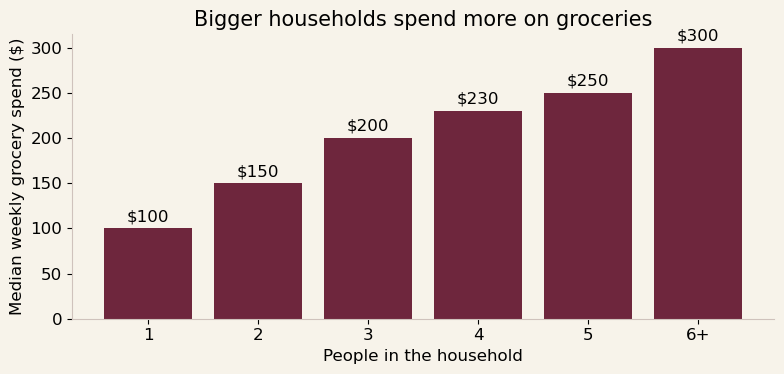

In [57]:
size_group = df['household_size'].clip(upper=6)   # 6 means six or more people
by_size = df.groupby(size_group)['weekly_grocery'].median()

plt.figure(figsize=(8, 3.9))
bars = plt.bar(['1', '2', '3', '4', '5', '6+'], by_size.values, color=BERRY)
plt.bar_label(bars, fmt='$%.0f', padding=3)
plt.title('Bigger households spend more on groceries')
plt.xlabel('People in the household')
plt.ylabel('Median weekly grocery spend ($)')
finish_chart('chart1_household_size.png')

Each extra person adds to the weekly grocery bill, from \$100 for one person to \$300 for six or more. This is the strongest pattern we found.

### Chart 2: Grocery spending by income group

Each of the five groups holds 20% of households. First we print where each group starts and ends.

In [58]:
# Where the five income groups start and end (after the cap)
df['income'].quantile([0.2, 0.4, 0.6, 0.8]).round(-3)

0.2     30000.0
0.4     57000.0
0.6     95000.0
0.8    160000.0
Name: income, dtype: float64

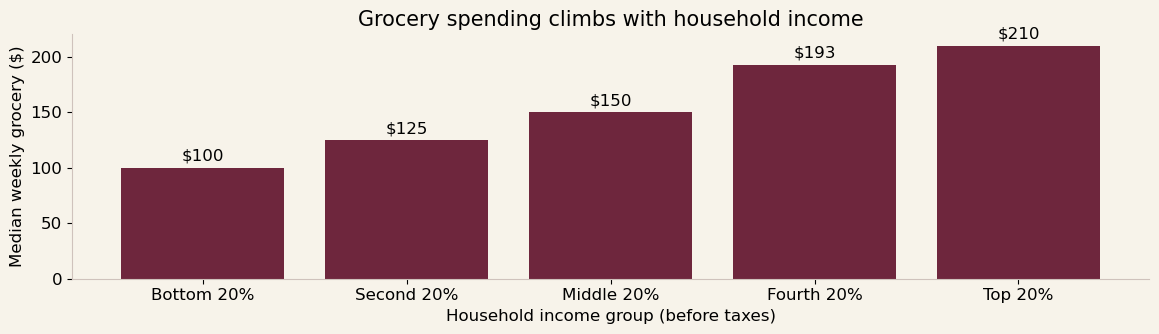

In [59]:
income_group = pd.qcut(df['income'], 5, labels=['Bottom 20%', 'Second 20%', 'Middle 20%', 'Fourth 20%', 'Top 20%'])
by_income = df.groupby(income_group, observed=True)['weekly_grocery'].median()

plt.figure(figsize=(11.75, 3.5))
bars = plt.bar(by_income.index.astype(str), by_income.values, color=BERRY)
plt.bar_label(bars, fmt='$%.0f', padding=3)
plt.title('Grocery spending climbs with household income')
plt.xlabel('Household income group (before taxes)')
plt.ylabel('Median weekly grocery ($)')
finish_chart('chart2_income.png')

The top income group (above \$160,000) spends about twice as much per week as the bottom group (below \$30,000).

### Chart 3: High spenders by household type

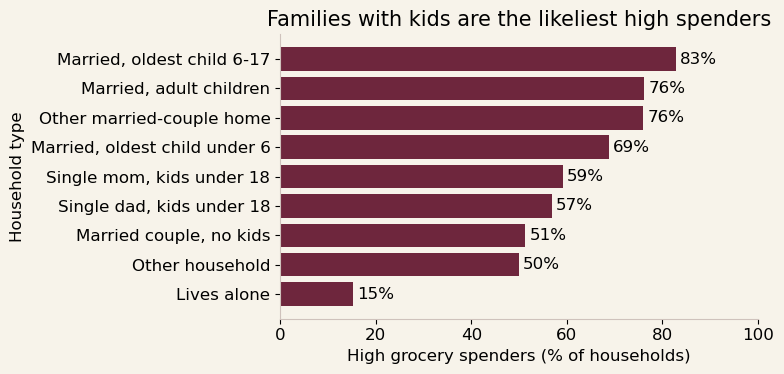

In [60]:
by_type = df.groupby('household_type')['high_spender'].mean().sort_values() * 100

plt.figure(figsize=(8, 3.9))
bars = plt.barh(by_type.index, by_type.values, color=BERRY)
plt.bar_label(bars, fmt='%.0f%%', padding=3)
plt.title('Families with kids are the likeliest high spenders')
plt.xlabel('High grocery spenders (% of households)')
plt.ylabel('Household type')
plt.xlim(0, 100)
finish_chart('chart3_household_type.png')

Married couples with kids at home, especially kids aged 6 to 17, are the most likely to be high spenders. Only 15% of people who live alone are.

### Chart 4: Model comparison on the test set

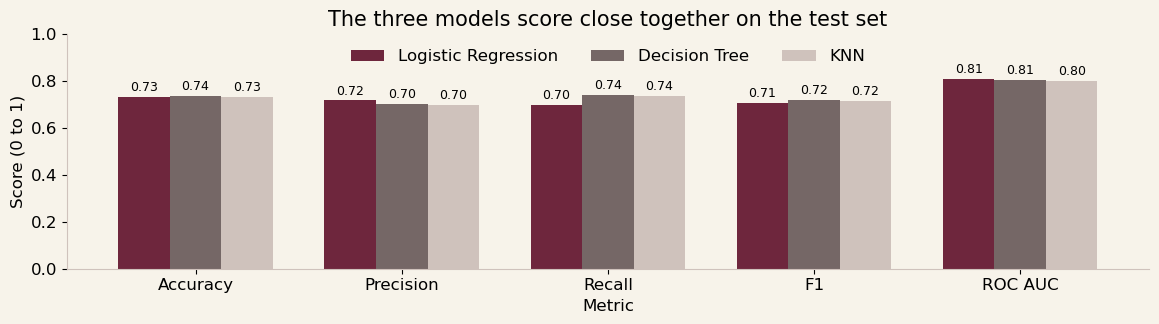

In [61]:
plot_data = results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']].T

ax = plot_data.plot(kind='bar', figsize=(11.75, 3.4), color=[BERRY, GRAY, LIGHT], rot=0, width=0.75)
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt='%.2f', fontsize=9, padding=2)
ax.set_ylim(0, 1)
ax.set_title('The three models score close together on the test set')
ax.set_xlabel('Metric')
ax.set_ylabel('Score (0 to 1)')
ax.legend(ncol=3, loc='upper center', frameon=False)
finish_chart('chart4_model_comparison.png')

The three models are within about a point of each other on accuracy and ROC AUC. The biggest difference is recall: the decision tree (0.740) beats logistic regression (0.700). Logistic regression wins on precision and ROC AUC.

### Chart 5: What drives the prediction

These are the ten biggest logistic regression coefficients. Berry bars push a household toward high spending, and gray bars push it away.

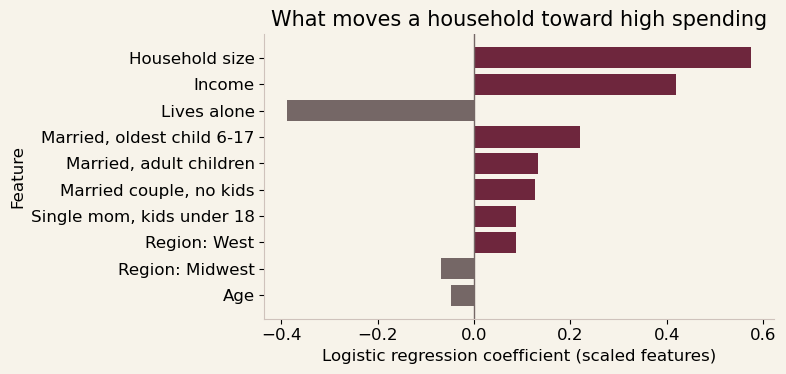

In [62]:
top = coefs.reindex(coefs.abs().sort_values().index).tail(10)
names = {'household_size': 'Household size', 'income': 'Income', 'age': 'Age'}
top.index = [names.get(n, n.replace('type: ', '').replace('region: ', 'Region: ')) for n in top.index]
colors = [BERRY if value > 0 else GRAY for value in top.values]

plt.figure(figsize=(8, 3.9))
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color=GRAY, linewidth=1)
plt.title('What moves a household toward high spending')
plt.xlabel('Logistic regression coefficient (scaled features)')
plt.ylabel('Feature')
finish_chart('chart5_drivers.png')

Household size and income matter most, and living alone pushes the hardest the other way. Region and age barely change the prediction.

### Chart 6: Targeting payoff

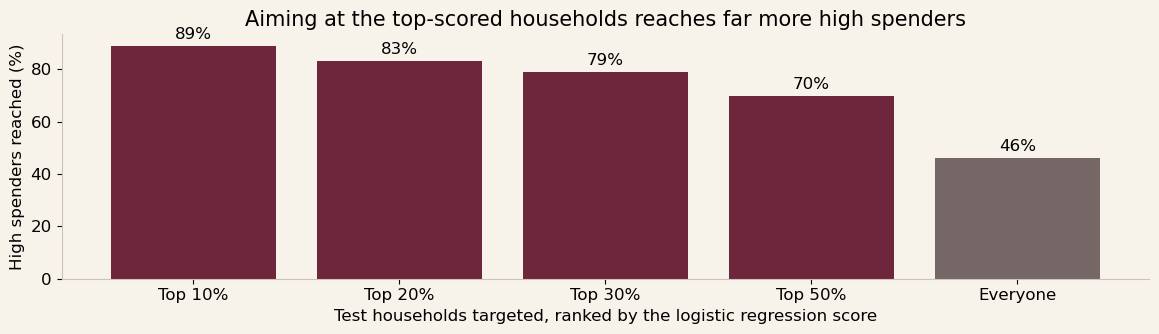

In [63]:
shares = [0.1, 0.2, 0.3, 0.5, 1.0]
hit_rates = [test_view.head(int(len(test_view) * s))['actual'].mean() * 100 for s in shares]

plt.figure(figsize=(11.75, 3.5))
bars = plt.bar(['Top 10%', 'Top 20%', 'Top 30%', 'Top 50%', 'Everyone'], hit_rates,
               color=[BERRY, BERRY, BERRY, BERRY, GRAY])
plt.bar_label(bars, fmt='%.0f%%', padding=3)
plt.title('Aiming at the top-scored households reaches far more high spenders')
plt.xlabel('Test households targeted, ranked by the logistic regression score')
plt.ylabel('High spenders reached (%)')
finish_chart('chart6_targeting.png')

Targeting the top-scored 10% of households reaches high spenders 89% of the time, compared to 46% with no targeting.